In [3]:
%pip install -U langgraph langchain-openai

   ---------------------------------------- 0.0/573.8 kB ? eta -:--:--
   ---------------------------------------- 573.8/573.8 kB 2.8 MB/s  0:00:00
   ---------------------------------------- 0.0/869.0 kB ? eta -:--:--
   ------------------------------------ --- 786.4/869.0 kB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 869.0/869.0 kB 3.9 MB/s  0:00:00

  Attempting uninstall: langsmith

    Found existing installation: langsmith 0.14.7

   ----- ---------------------------------- 1/8 [langsmith]
   ----- ---------------------------------- 1/8 [langsmith]
    Uninstalling langsmith-0.14.7:
   ----- ---------------------------------- 1/8 [langsmith]
      Successfully uninstalled langsmith-0.14.7
   ----- ---------------------------------- 1/8 [langsmith]
   ----- ---------------------------------- 1/8 [langsmith]
   ----- ---------------------------------- 1/8 [langsmith]
   ----- ---------------------------------- 1/8 [langsmith]
   ----- -------------------------

In [4]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI

In [5]:
from typing import TypedDict
from dotenv import load_dotenv

In [6]:
import os
load_dotenv(override=True)

True

In [7]:
def get_groq_llm():
    return ChatOpenAI(
        model= "openai/gpt-oss-120b",
        base_url= "https://api.groq.com/openai/v1",
        api_key= os.getenv("GROQ_API_KEY"),
        max_tokens= 1000
    )

In [8]:
llm= get_groq_llm()

In [9]:
class LLMState(TypedDict):
    question: str
    answer: str

In [10]:
def chat_llm(state: LLMState):

    question= state['question']

    ##prompt:
    prompt= f'Answer the following Question {question}'

    answer= llm.invoke(prompt).content
    
    state['answer']= answer

    return state


    


In [11]:
graph= StateGraph(LLMState)

## add nodes

graph.add_node('chat_llm',chat_llm)

In [12]:
## add edges

graph.add_edge(START,'chat_llm')
graph.add_edge('chat_llm', END)

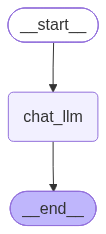

In [14]:
workflow= graph.compile()

workflow

In [20]:
intial_state= {'question':'How far is the jorhat from Guwahati'}

final_state= workflow.invoke(intial_state)

print(final_state)

{'question': 'How far is the jorhat from Guwahati', 'answer': '**Distance between Jorhat and Guwahati (Assam, India)**  \n\n| Mode of measurement | Approximate distance |\n|---------------------|----------------------|\n| **Road distance (via NH 27)** | **≈\u202f260\u202f–\u202f280\u202fkm** (about 5–6\u202fhours by car or bus, depending on traffic and road conditions) |\n| **Straight‑line (as‑the‑crow‑flies) distance** | **≈\u202f210\u202fkm** (≈\u202f130\u202fmiles) |\n| **Rail distance (train route)** | **≈\u202f270\u202fkm** (travel time 5–7\u202fhours, depending on the train service) |\n\n### Typical travel options\n\n| Mode | Typical travel time | Remarks |\n|------|--------------------|---------|\n| **Car / Taxi** | 5–6\u202fhours | Take NH\u202f27 eastward from Guwahati → Nagaon → Morigaon → Jorhat. The highway is generally in good condition, but monsoon rains can cause delays. |\n| **Bus** | 5.5–7\u202fhours | Several state‑run (ASTC) and private operators run daily services. 

In [21]:
print(final_state['answer'])

**Distance between Jorhat and Guwahati (Assam, India)**  

| Mode of measurement | Approximate distance |
|---------------------|----------------------|
| **Road distance (via NH 27)** | **≈ 260 – 280 km** (about 5–6 hours by car or bus, depending on traffic and road conditions) |
| **Straight‑line (as‑the‑crow‑flies) distance** | **≈ 210 km** (≈ 130 miles) |
| **Rail distance (train route)** | **≈ 270 km** (travel time 5–7 hours, depending on the train service) |

### Typical travel options

| Mode | Typical travel time | Remarks |
|------|--------------------|---------|
| **Car / Taxi** | 5–6 hours | Take NH 27 eastward from Guwahati → Nagaon → Morigaon → Jorhat. The highway is generally in good condition, but monsoon rains can cause delays. |
| **Bus** | 5.5–7 hours | Several state‑run (ASTC) and private operators run daily services. Overnight buses are also available. |
| **Train** | 5–7 hours | Direct trains (e.g., Guwahati‑Jorhat Intercity Express, Guwahati‑Jorhat Passenger) run 

In [24]:
intial_state= {'question':'okay great but how far is jorhat from Tezpur airport?'}

final_state= workflow.invoke(intial_state)

In [25]:
print(final_state)

{'question': 'okay great but how far is jorhat from Tezpur airport?', 'answer': '**Distance & Travel Time**\n\n- **Road distance:** Approximately **140\u202f–\u202f150\u202fkm** (≈\u202f87\u202f–\u202f93\u202fmiles) between Jorhat city and **Tezpur Airport (Salonibari Airport, IATA: TEZ)**.  \n- **Typical driving time:** **3\u202f–\u202f4\u202fhours**, depending on traffic, road conditions, and exact start/end points.\n\n**How to Get There**\n\n| Mode of transport | Typical route / notes | Approx. time |\n|-------------------|-----------------------|--------------|\n| **Car / Taxi** | Take **NH‑715** (Jorhat → Sivasagar → Amguri) then continue on **NH‑15** toward Tezpur. The last stretch (≈\u202f15\u202fkm) leads to the airport on the south side of Tezpur. | 3\u202f–\u202f4\u202fh |\n| **Bus** | State Transport (ASTC) and private operators run regular services between Jorhat and Tezpur. Get off at the **Tezpur bus stand** and hire an auto‑rickshaw or taxi for the final 10\u202fkm to th

In [26]:
print(final_state['answer'])


**Distance & Travel Time**

- **Road distance:** Approximately **140 – 150 km** (≈ 87 – 93 miles) between Jorhat city and **Tezpur Airport (Salonibari Airport, IATA: TEZ)**.  
- **Typical driving time:** **3 – 4 hours**, depending on traffic, road conditions, and exact start/end points.

**How to Get There**

| Mode of transport | Typical route / notes | Approx. time |
|-------------------|-----------------------|--------------|
| **Car / Taxi** | Take **NH‑715** (Jorhat → Sivasagar → Amguri) then continue on **NH‑15** toward Tezpur. The last stretch (≈ 15 km) leads to the airport on the south side of Tezpur. | 3 – 4 h |
| **Bus** | State Transport (ASTC) and private operators run regular services between Jorhat and Tezpur. Get off at the **Tezpur bus stand** and hire an auto‑rickshaw or taxi for the final 10 km to the airport. | 4 – 5 h (including wait time) |
| **Train + Taxi** | Nearest railway stations: **Jorhat Town (JTTN)** or **Jorhat (JRH)** → **Tezpur (TPU)** (via a few connec

## Call to llm:
## Stateless Calls: It does not have any previous message history



##

User_query_no1: hsxbshbxh
llm: hsxbhjsxhbv

user_q2: follow up question
llm: proper answe

## sending all prev, info to llm